# Modeling

**Goal:** train and compare models that predict the energy use of non-residential buildings in Seattle, starting from the features built in `02_feature_engineering.ipynb`.

## 0. Setup

Imports, display conventions (matplotlib style, number formats of the tables) and load the dataset with the engineered features.

`buildings_feature_engineered.parquet` is the output of `02_feature_engineering.ipynb`.

To generate it, run `notebooks/01_eda.ipynb` then `notebooks/02_feature_engineering.ipynb` from top to bottom. The file is written to `data/processed/buildings_feature_engineered.parquet`.

In [82]:
from collections.abc import Callable
from functools import partial
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from catboost import CatBoostRegressor
from IPython.display import display
from pandas.io.formats.style import Styler
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    get_scorer,
    make_scorer,
    mean_absolute_error,
    r2_score,
    root_mean_squared_error,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

# Matplotlib style, set once for all the figures
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "axes.axisbelow": True,
        "grid.color": "#e5e5e5",
        "legend.frameon": False,
    }
)

# Number format of each column of the result tables, defined once
FORMATS = {
    "log10 MAE": "{:.3f}",
    "std": "{:.3f}",
    "gap": "{:.3f}",
    "within ±25%": "{:.0%}",
    "within ±50%": "{:.0%}",
    "median error": "{:.0%}",
    "fit time (s)": "{:.2f}",
    "R2": "{:.3f}",
    "MAE (kBtu)": "{:,.0f}",
    "RMSE (kBtu)": "{:,.0f}",
    "total bias": "{:+.1%}",
    "Actual": "{:,.0f}",
    "Predicted": "{:,.0f}",
    "Predicted/Actual ratio": "{:.2f}",
    "Area": "{:,.0f}",
    "Median intensity": "{:,.0f}",
}


def styled(table: pd.DataFrame) -> Styler:
    """Style a table with FORMATS: a column takes the format of the longest key it starts
    with, so 'log10 MAE (CV)' and 'R2 (all)' use the formats of 'log10 MAE' and 'R2'.
    """
    keys = sorted(FORMATS, key=len, reverse=True)
    formats = {}
    for column in table.columns:
        key = next((k for k in keys if column.startswith(k)), None)
        if key is not None:
            formats[column] = FORMATS[key]
    return table.style.format(formats)


df = pd.read_parquet("../data/processed/buildings_feature_engineered.parquet")
print(f"Dataset: {df.shape[0]} rows x {df.shape[1]} columns")

Dataset: 1535 rows x 12 columns


## 1. Train/test split

The test set is set aside now and is only used once, for the final evaluation. Everything else (imputation, encoding, feature selection, hyperparameters) is fitted on the training set only, inside the cross-validation.

- **Split:** 80% train / 20% test, fixed `random_state` for reproducibility.
- **Target:** `SiteEnergyUse(kBtu)` is right-skewed, so it is modeled as `log10` (decision of notebook 1). `y` is kept in kBtu: the model will be wrapped in a `TransformedTargetRegressor` (`func=np.log10`), which fits on `log10(y)` and returns predictions in kBtu, so the metrics are computed in kBtu.
- **Stratification:** a continuous target cannot be stratified directly. The target is cut into 10 quantile bins (deciles; the bins are identical on `y` and on `log10(y)`, since the log is monotonic), and the split is stratified on these bins so that the training and test sets cover the whole range of consumption, including the few very large buildings. The bins are computed on the whole dataset, but they are only used to draw the split: they are not a feature and never reach the models.

The check below compares the `log10` target distributions of the two sets (the log is only computed for display).

In [56]:
TARGET = "SiteEnergyUse(kBtu)"
RANDOM_STATE = 42

X = df.drop(columns=TARGET)
y = df[TARGET]  # kBtu; the log10 transform is done by TransformedTargetRegressor

# Stratify on deciles of the target (the bins are the same on y and log10(y))
y_bins = pd.qcut(y, q=10, labels=False)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y_bins, random_state=RANDOM_STATE
)
print(f"Train: {len(X_train)} rows | Test: {len(X_test)} rows")

Train: 1228 rows | Test: 307 rows


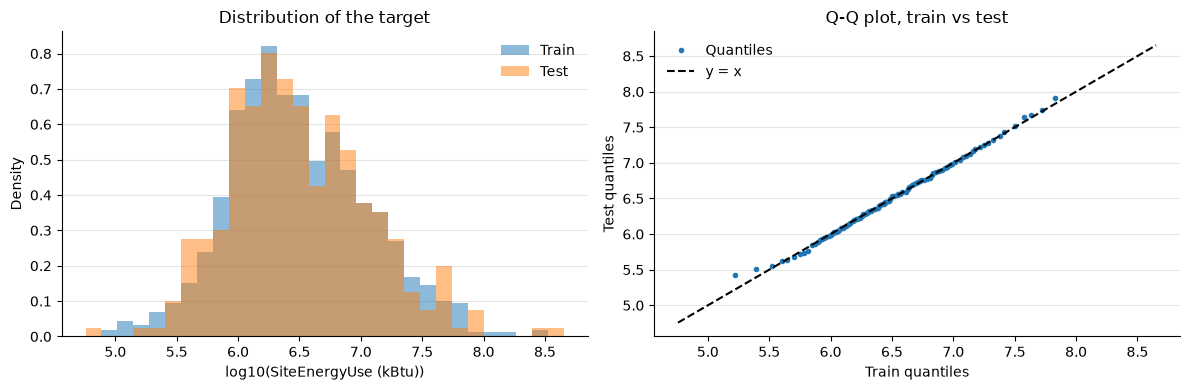

,Train,Test
count,1228.000,307.000
mean,6.492,6.498
std,0.564,0.577
min,4.902,4.757
25%,6.101,6.087
50%,6.437,6.429
75%,6.861,6.872
max,8.467,8.652


In [57]:
# Check: log10(y) distributions of the two sets (for display only)
log_train, log_test = np.log10(y_train), np.log10(y_test)
log_all = np.log10(y)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

bins = np.linspace(log_all.min(), log_all.max(), 31)
axes[0].hist(log_train, bins=bins, density=True, alpha=0.5, label="Train")
axes[0].hist(log_test, bins=bins, density=True, alpha=0.5, label="Test")
axes[0].set_xlabel("log10(SiteEnergyUse (kBtu))")
axes[0].set_ylabel("Density")
axes[0].set_title("Distribution of the target")
axes[0].legend()

quantiles = np.linspace(0.01, 0.99, 99)
axes[1].plot(
    log_train.quantile(quantiles), log_test.quantile(quantiles), ".", label="Quantiles"
)
axes[1].plot(
    [log_all.min(), log_all.max()], [log_all.min(), log_all.max()], "k--", label="y = x"
)
axes[1].set_xlabel("Train quantiles")
axes[1].set_ylabel("Test quantiles")
axes[1].set_title("Q-Q plot, train vs test")
axes[1].legend()

plt.tight_layout()
plt.show()

summary = pd.DataFrame({"Train": log_train.describe(), "Test": log_test.describe()})
display(summary.round(3))

In [58]:
counts = (
    pd.DataFrame(
        {
            "Train": X_train["PrimaryPropertyType"].value_counts(),
            "Test": X_test["PrimaryPropertyType"].value_counts(),
        }
    )
    .fillna(0)
    .astype(int)
)
counts["Test share"] = (counts["Test"] / (counts["Train"] + counts["Test"])).round(3)
counts.sort_values("Train", ascending=False)

,Train,Test,Test share
PrimaryPropertyType,,,
Small- and Mid-Sized Office,226,60,0.210
Other,197,48,0.196
Warehouse,147,38,0.205
Large Office,131,38,0.225
Mixed Use Property,80,24,0.231
Retail Store,73,12,0.141
Hotel,57,18,0.240
Worship Facility,56,13,0.188
Distribution Center,49,4,0.075


### Checks

- The stratification works. The two sets have almost the same mean (6.49 vs 6.50 in log10), median (6.44 vs 6.43) and spread, and the points of the Q-Q plot follow the diagonal over the whole range, including the largest consumers.
- The target is strictly positive (minimum of 4.76 in log10), so the log10 transform is always defined. The largest building of the test set (8.65) is above the maximum of the training set (8.47): the models will have to predict beyond the values they were trained on.
- Most property types have about 20% of their buildings in the test set. By chance, no hospital ends up in the test set. The split is kept as is: changing the random seed to fix this would mean choosing the test set after looking at it. The behavior of the models on hospitals is assessed through cross-validation instead, where each building is used once for validation.

## 2. Checks on the training set

Everything in this section uses `X_train` only. The exploration of notebooks 1 and 2 is not repeated: this section only keeps the checks that drive a preprocessing choice.

### Rare property types

Notebook 1 shows that the rarest property types (8 to 10 buildings in the training set, see the table above) are among the most extreme in energy use per sq ft: laboratories, hospitals, refrigerated warehouses. Grouping rare categories at encoding time (`min_frequency`, `max_categories`) would merge them and lose the strongest signal of the dataset, so all property types are kept as separate categories.

### Redundancy among the size variables

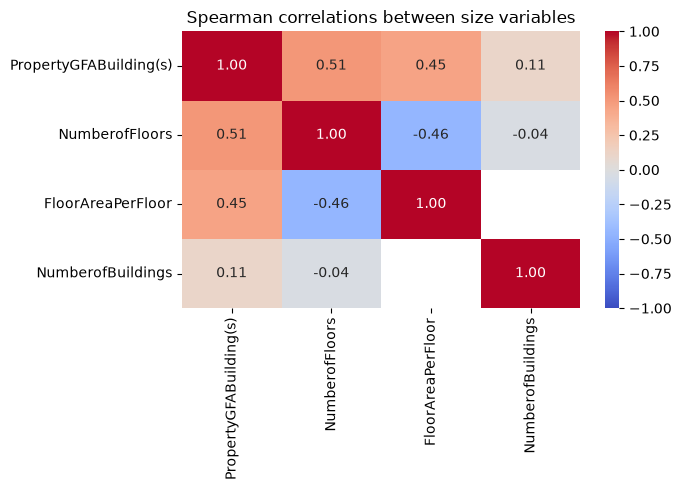

In [79]:
size_cols = [
    "PropertyGFABuilding(s)",
    "NumberofFloors",
    "FloorAreaPerFloor",
    "NumberofBuildings",
]

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    X_train[size_cols].corr(method="spearman"),
    annot=True,
    fmt=".2f",
    vmin=-1,
    vmax=1,
    cmap="coolwarm",
    ax=ax,
)
ax.grid(False)
ax.set_title("Spearman correlations between size variables")
plt.tight_layout()
plt.show()

- The size variables are moderately correlated (0.45 to 0.51), and `NumberofBuildings` is almost independent of them.
- By construction, area = floors × area per floor: any one of the three can be computed exactly from the other two. The linear model therefore gets only two of them. Tree-based models can keep all three, but their importance will have to be read together.
- `FloorAreaPerFloor` is missing for all campuses (hence the empty cell in the heatmap), so its missing values carry information: an indicator column will be added at imputation.

## 3. Preprocessing

Three preprocessors, one per model. All are `ColumnTransformer`s that will be the first step of a pipeline, so that imputation, scaling and encoding are fitted on the training folds only.

| | Linear models | Random forest | CatBoost |
|---|---|---|---|
| Skewed sizes (`PropertyGFABuilding(s)`, `NumberofFloors`, `NumberofBuildings`) | `log10` | as is (trees only use the order of the values) | as is |
| Size variables | area + floors; `FloorAreaPerFloor` is dropped (area = floors × area per floor, a linear model cannot take all three) | all three | all three |
| Missing values (`FloorAreaPerFloor`, `NumberofFloors`) | median + missing indicator (`NumberofFloors` only) | median + missing indicator | median + missing indicator |
| Scaling | `StandardScaler` on the numeric variables (needed for regularisation); binary variables and missing indicators are never scaled, to stay readable | none | none |
| Categories (`PrimaryPropertyType`, `Neighborhood`, `ConstructionPeriod`) | one-hot, unknown category ignored | one-hot, unknown category ignored | as is (CatBoost handles categories natively) |
| `ParkingShare`, `Latitude`, `Longitude` | scaled | as is | as is |
| `HasMixedUsage` (binary) | as is | as is | as is |

- The missing `FloorAreaPerFloor` values are mostly campuses (see section 2). The tree models keep the missing indicator for them. The linear model does not use this feature, so `NumberofBuildings` is its only campus signal. An indicator only exists for columns with missing values in the training data.
- No `min_frequency` in the one-hot encoding: the rare property types are the most extreme ones and must keep their own column.
- Which of the three size variables to drop for the linear model is a modeling choice: `FloorAreaPerFloor` is dropped because it has more imputed values (51, against 11 for `NumberofFloors`), and floor area has no physical meaning for a campus.

In [62]:
X_train.isna().sum()

PropertyGFABuilding(s)     0
PrimaryPropertyType        0
NumberofFloors            11
NumberofBuildings          0
Neighborhood               0
Latitude                   0
Longitude                  0
ParkingShare               0
HasMixedUsage              0
ConstructionPeriod         0
FloorAreaPerFloor         51
dtype: int64

In [63]:
CATEGORICAL = ["PrimaryPropertyType", "Neighborhood", "ConstructionPeriod"]
LOG_COLS = ["PropertyGFABuilding(s)", "NumberofFloors", "NumberofBuildings"]
PLAIN_NUMERIC_COLS = [
    "ParkingShare",
    "Latitude",
    "Longitude",
]  # no log; scaled for the linear models only
BINARY_COLS = ["HasMixedUsage"]  # already 0/1, never scaled
TREE_ONLY_COLS = [
    "FloorAreaPerFloor"
]  # redundant with the two size variables for a linear model


def make_one_hot():
    return OneHotEncoder(handle_unknown="ignore", sparse_output=False)


def make_imputer(add_indicator):
    return SimpleImputer(strategy="median", add_indicator=add_indicator)


def make_linear_preprocessor():
    """Log of the skewed sizes, scaling, imputation, one-hot encoding.

    The missing indicator is generated by its own step, outside of the sub-pipeline,
    so that it is not scaled.
    """
    log_pipeline = make_pipeline(
        FunctionTransformer(np.log10, feature_names_out="one-to-one"),
        StandardScaler(),
        make_imputer(add_indicator=False),
    )
    return ColumnTransformer(
        [
            ("log", log_pipeline, LOG_COLS),
            ("missing", MissingIndicator(features="missing-only"), ["NumberofFloors"]),
            ("plain_numeric", StandardScaler(), PLAIN_NUMERIC_COLS),
            ("binary", "passthrough", BINARY_COLS),
            ("cat", make_one_hot(), CATEGORICAL),
        ],
        remainder="drop",  # FloorAreaPerFloor
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")


def make_tree_preprocessor():
    """No transformation of the values: imputation (with indicator) and one-hot encoding."""
    return ColumnTransformer(
        [
            ("num", make_imputer(add_indicator=True), LOG_COLS + TREE_ONLY_COLS),
            ("plain", "passthrough", PLAIN_NUMERIC_COLS + BINARY_COLS),
            ("cat", make_one_hot(), CATEGORICAL),
        ],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")


def make_catboost_preprocessor():
    """No transformation of the values: imputation (with indicator).

    Categories are encoded by CatBoost itself (ordered target statistics) via cat_features.
    """
    return ColumnTransformer(
        [
            ("num", make_imputer(add_indicator=True), LOG_COLS + TREE_ONLY_COLS),
            ("plain", "passthrough", PLAIN_NUMERIC_COLS + BINARY_COLS),
            ("cat", "passthrough", CATEGORICAL),
        ],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")

### Check

Each preprocessor is fitted on the training set and applied to both sets (only to check the output: during the modeling, the fit happens inside the cross-validation). The output must have no missing value, and the linear one must have centered numeric columns.

In [64]:
for name, make in [
    ("Linear", make_linear_preprocessor),
    ("Trees", make_tree_preprocessor),
    ("CatBoost", make_catboost_preprocessor),
]:
    prep = make().fit(X_train)
    out_train, out_test = prep.transform(X_train), prep.transform(X_test)
    assert not out_train.isna().any().any() and not out_test.isna().any().any()
    print(f"{name}: {X_train.shape[1]} -> {out_train.shape[1]} columns")
    indicators = [c for c in out_train.columns if c.startswith("missingindicator")]
    print(f"  missing indicators: {indicators}")

linear_out = make_linear_preprocessor().fit_transform(X_train)
linear_out.iloc[:, :6].astype(float).describe().loc[
    ["mean", "std", "min", "max"]
].round(2)

Linear: 11 -> 46 columns
  missing indicators: ['missingindicator_NumberofFloors']
Trees: 11 -> 48 columns
  missing indicators: ['missingindicator_NumberofFloors', 'missingindicator_FloorAreaPerFloor']
CatBoost: 11 -> 13 columns
  missing indicators: ['missingindicator_NumberofFloors', 'missingindicator_FloorAreaPerFloor']


,PropertyGFABuilding(s),NumberofFloors,NumberofBuildings,missingindicator_NumberofFloors,ParkingShare,Latitude
mean,0.00,-0.00,-0.00,0.01,0.00,0.00
std,1.00,1.00,1.00,0.09,1.00,1.00
min,-1.82,-1.14,-0.17,0.00,-0.45,-2.26
max,3.77,3.90,11.81,1.00,5.10,2.48


## 4. Evaluation protocol

| Element | Choice |
|---|---|
| Cross-validation | 5 folds, stratified on the deciles of `y_train`, built once and shared by all the models |
| Decision metric | MAE on `log10` (`log10_mae`), with the same weight for small and large buildings. It ranks the models, but its value is hard to read on its own |
| Readable metrics | Share of buildings predicted within ±25% and within ±50% of their actual energy use, and the median relative error (half of the buildings have a smaller error) |
| Metrics in kBtu | R², MAE and RMSE, dominated by the largest buildings, and the total bias: total predicted energy use vs total actual energy use |
| Baselines | A `DummyRegressor` (sanity floor) and a business rule, building area × median intensity of the property type: **the reference to beat** |
| Overfitting signal | Gap between the mean train and validation scores (positive when the model does worse on validation) |

All the models learn `log10(y)` through a `TransformedTargetRegressor` and predict in kBtu.

`evaluate_model` cross-validates a model and returns one row of the results table; `decision_table` and `kbtu_table` display the results.

In [65]:
def evaluate_model(
    model: Any,
    X: pd.DataFrame,
    y: pd.Series,
    cv: list[tuple[np.ndarray, np.ndarray]],
    scorers: dict[str, str | Callable],
    model_name: str,
) -> dict[str, Any]:
    """Cross-validate a model on explicit folds and return one row of the summary table.

    Train and validation scores are averaged over the folds (mean and std). Keys starting
    with 'neg_' are errors: the sign is flipped back and the prefix removed. The gap is
    positive when the model does worse on validation (val - train for errors, train - val otherwise).
    """
    results = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scorers,
        return_train_score=True,
    )

    row: dict[str, Any] = {
        "model": model_name,
        "fit_time_mean": results["fit_time"].mean(),
    }
    for key in scorers:
        is_error = key.startswith("neg_")
        name = key.removeprefix("neg_")
        sign = -1 if is_error else 1  # scikit-learn negates errors: flip them back

        train = sign * results[f"train_{key}"]
        val = sign * results[f"test_{key}"]

        row[f"{name}_train_mean"] = train.mean()
        row[f"{name}_train_std"] = train.std()
        row[f"{name}_val_mean"] = val.mean()
        row[f"{name}_val_std"] = val.std()
        row[f"{name}_gap"] = (
            val.mean() - train.mean() if is_error else train.mean() - val.mean()
        )
    return row


def with_log_target(regressor: Any) -> TransformedTargetRegressor:
    """Wrap a regressor so that it learns log10(y) and predicts in kBtu."""
    return TransformedTargetRegressor(
        regressor=regressor, func=np.log10, inverse_func=partial(np.power, 10.0)
    )


def decision_table(results: pd.DataFrame) -> Styler:
    """Validation scores used to compare the models; the best log10 MAE is in bold."""
    table = pd.DataFrame(
        {
            "log10 MAE": results["log10_mae_val_mean"],
            "std": results["log10_mae_val_std"],
            "gap": results["log10_mae_gap"],
            "within ±25%": results["within_25_val_mean"],
            "within ±50%": results["within_50_val_mean"],
            "median error": results["median_ape_val_mean"],
            "fit time (s)": results["fit_time_mean"],
        }
    )
    return styled(table).highlight_min(subset=["log10 MAE"], props="font-weight: bold")


def kbtu_table(results: pd.DataFrame) -> Styler:
    """Validation R2, MAE, RMSE in kBtu and total bias, one row per model."""
    table = pd.DataFrame(
        {
            "R2": results["r2_val_mean"],
            "MAE (kBtu)": results["mean_absolute_error_val_mean"],
            "RMSE (kBtu)": results["root_mean_squared_error_val_mean"],
            "total bias": results["total_bias_val_mean"],
        }
    )
    return styled(table)

### Folds and scorers

The folds are stratified on the deciles of `y_train` (recomputed on the training set) and built once, so that every model is evaluated on the same folds.

In [66]:
y_train_bins = pd.qcut(y_train, q=10, labels=False)

cv = list(
    StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(
        X_train, y_train_bins
    )
)

for i, (train_idx, val_idx) in enumerate(cv, start=1):
    print(f"Fold {i}: train {len(train_idx)} rows | validation {len(val_idx)} rows")
assert sorted(np.concatenate([val for _, val in cv])) == list(range(len(X_train)))

Fold 1: train 982 rows | validation 246 rows
Fold 2: train 982 rows | validation 246 rows
Fold 3: train 982 rows | validation 246 rows
Fold 4: train 983 rows | validation 245 rows
Fold 5: train 983 rows | validation 245 rows


In [67]:
def log10_mae(y_true, y_pred):
    return mean_absolute_error(np.log10(y_true), np.log10(y_pred))


def share_within(y_true, y_pred, tol):
    """Share of buildings predicted within ±tol of their actual energy use (0.25 = ±25%)."""
    return np.mean(np.abs(y_pred - y_true) / y_true <= tol)


def median_ape(y_true, y_pred):
    """Median relative error: half of the buildings have a smaller error."""
    return np.median(np.abs(y_pred - y_true) / y_true)


def total_bias(y_true, y_pred):
    """Relative gap between the total predicted and the total actual energy use."""
    return y_pred.sum() / y_true.sum() - 1


scorers = {
    "r2": "r2",
    "neg_mean_absolute_error": "neg_mean_absolute_error",
    "neg_root_mean_squared_error": "neg_root_mean_squared_error",
    "neg_log10_mae": make_scorer(log10_mae, greater_is_better=False),
    "within_25": make_scorer(share_within, tol=0.25),
    "within_50": make_scorer(share_within, tol=0.5),
    "neg_median_ape": make_scorer(median_ape, greater_is_better=False),
    "total_bias": make_scorer(total_bias),
}

### Baselines

Two references, evaluated on the same folds as the models:

- **Dummy model**: a `DummyRegressor` that predicts the mean of `log10(y)` for every building (the geometric mean in kBtu), wrapped with `with_log_target` like the other models. It learns nothing from the features: it is a sanity floor that every model must beat by far. Its R² is slightly negative by construction: R² compares the predictions with the average consumption (about 8.0 million kBtu), while the dummy predicts a typical building (about 3.1 million kBtu).
- **Business rule**: building area × median energy use per sq ft of the property type, learned on the training folds. It is what the city could compute without machine learning, from the two strongest signals of the exploration (area and type). **It is the reference to beat**: a model is only worth it if it does better than this rule.

In [68]:
class TypeIntensityBaseline(RegressorMixin, BaseEstimator):
    """Business rule: building area x median intensity of the property type, in kBtu.

    The median log10 intensity of each type is learned on the training data; a type
    unseen during fit gets the overall median.
    """

    def fit(self, X, y):
        log_intensity = np.log10(y / X["PropertyGFABuilding(s)"])
        self.medians_ = log_intensity.groupby(X["PrimaryPropertyType"]).median()
        self.global_median_ = log_intensity.median()
        return self

    def predict(self, X):
        log_intensity = (
            X["PrimaryPropertyType"]
            .map(self.medians_)
            .astype(float)
            .fillna(self.global_median_)
        )
        return (10**log_intensity * X["PropertyGFABuilding(s)"]).to_numpy()


baselines = {
    "Dummy (mean of log10)": with_log_target(DummyRegressor(strategy="mean")),
    "Business rule (area x type)": TypeIntensityBaseline(),
}
baseline_rows = [
    evaluate_model(model, X_train, y_train, cv, scorers, name)
    for name, model in baselines.items()
]
baseline_results = pd.DataFrame(baseline_rows).set_index("model")
display(decision_table(baseline_results))
display(kbtu_table(baseline_results))

,log10 MAE,std,gap,within ±25%,within ±50%,median error,fit time (s)
model,,,,,,,
Dummy (mean of log10),0.451,0.004,-0.000,14%,29%,78%,0.01
Business rule (area x type),0.221,0.010,0.006,37%,63%,37%,0.00


,R2,MAE (kBtu),RMSE (kBtu),total bias
model,,,,
Dummy (mean of log10),-0.073,"6,657,011","19,144,851",-60.7%
Business rule (area x type),0.769,"3,090,725","8,263,563",-10.9%


## 5. Model comparison

Three models from three families, with their default settings, on the same folds:

- **Ridge** (linear model with L2 regularisation, `alpha=1`) on the linear preprocessor;
- **Random forest** (bagging of deep trees: 100 trees, no depth limit) on the tree preprocessor;
- **CatBoost** (boosting of symmetric trees: 1000 iterations of depth 6) on its own preprocessor, with native categorical features. `verbose=0` and `allow_writing_files=False` only silence the training log and the `catboost_info/` folder.

The hyperparameters are tuned in section 6.

In [69]:
models = {
    "Ridge (alpha=1)": with_log_target(
        make_pipeline(make_linear_preprocessor(), Ridge())
    ),
    "Random forest (default)": with_log_target(
        make_pipeline(
            make_tree_preprocessor(), RandomForestRegressor(random_state=RANDOM_STATE)
        )
    ),
    "CatBoost (default)": with_log_target(
        make_pipeline(
            make_catboost_preprocessor(),
            CatBoostRegressor(
                random_state=RANDOM_STATE,
                verbose=0,
                allow_writing_files=False,
                cat_features=tuple(CATEGORICAL),
            ),
        )
    ),
}

rows = baseline_rows + [
    evaluate_model(model, X_train, y_train, cv, scorers, name)
    for name, model in models.items()
]
results = pd.DataFrame(rows).set_index("model")
decision_table(results)

,log10 MAE,std,gap,within ±25%,within ±50%,median error,fit time (s)
model,,,,,,,
Dummy (mean of log10),0.451,0.004,-0.000,14%,29%,78%,0.01
Business rule (area x type),0.221,0.010,0.006,37%,63%,37%,0.00
Ridge (alpha=1),0.218,0.008,0.009,35%,64%,37%,0.04
Random forest (default),0.235,0.004,0.148,33%,62%,39%,0.70
CatBoost (default),0.223,0.005,0.082,34%,64%,38%,1.85


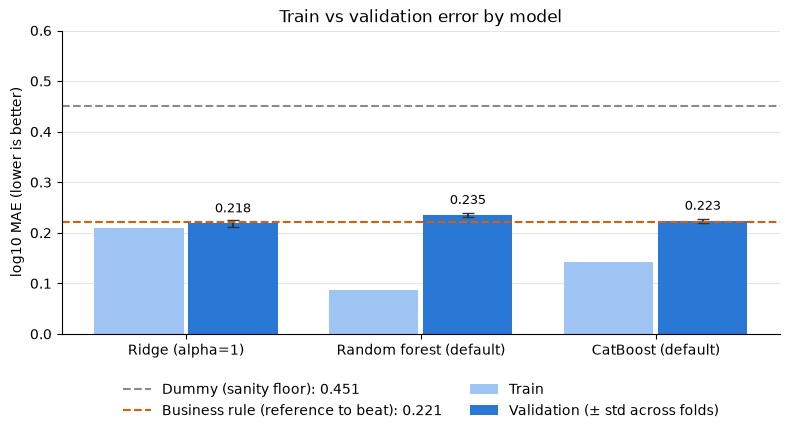

In [70]:
# Same data as the decision table: train vs validation log10 MAE, baselines as reference lines
compared = results.drop(index=list(baselines))
x = np.arange(len(compared))
width = 0.38

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(
    x - width / 2 - 0.01,
    compared["log10_mae_train_mean"],
    width,
    color="#9ec5f4",
    label="Train",
)
ax.bar(
    x + width / 2 + 0.01,
    compared["log10_mae_val_mean"],
    width,
    yerr=compared["log10_mae_val_std"],
    capsize=4,
    color="#2a78d6",
    ecolor="#333333",
    label="Validation (± std across folds)",
)
for xi, value in zip(x, compared["log10_mae_val_mean"]):
    ax.annotate(
        FORMATS["log10 MAE"].format(value),
        (xi + width / 2 + 0.01, value),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )

references = {
    "Dummy (mean of log10)": ("Dummy (sanity floor)", "#8a8a8a"),
    "Business rule (area x type)": ("Business rule (reference to beat)", "#d95f02"),
}
for name, (label, color) in references.items():
    value = results.loc[name, "log10_mae_val_mean"]
    ax.axhline(
        value,
        color=color,
        linestyle="--",
        linewidth=1.5,
        label=f"{label}: {FORMATS['log10 MAE'].format(value)}",
    )

ax.set_xticks(x, compared.index)
ax.set_ylim(0, 0.6)
ax.set_ylabel("log10 MAE (lower is better)")
ax.set_title("Train vs validation error by model")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.tight_layout()
plt.show()

In [71]:
kbtu_table(results)

,R2,MAE (kBtu),RMSE (kBtu),total bias
model,,,,
Dummy (mean of log10),-0.073,"6,657,011","19,144,851",-60.7%
Business rule (area x type),0.769,"3,090,725","8,263,563",-10.9%
Ridge (alpha=1),0.723,"3,304,013","9,233,231",-11.4%
Random forest (default),0.725,"3,416,659","9,346,998",-19.0%
CatBoost (default),0.723,"3,391,345","9,566,857",-17.4%


### Share of buildings within a given error

The same comparison, read differently: for each tolerance (±10%, ±20%, ...), the share of training buildings whose prediction falls within that tolerance of their actual energy use. The higher the curve, the better the model. The predictions are out-of-fold: each building is predicted by a model fitted without its fold, on the same folds as above.

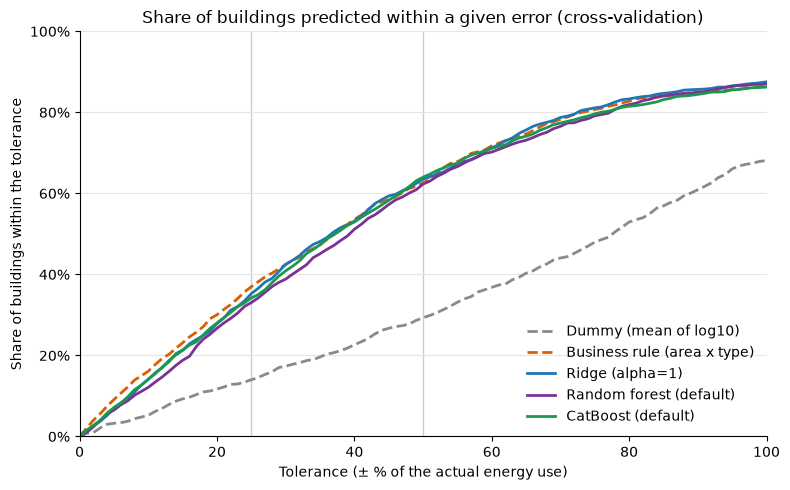

In [72]:
tolerances = np.linspace(0, 1, 101)
styles = {
    "Dummy (mean of log10)": {"color": "#8a8a8a", "linestyle": "--"},
    "Business rule (area x type)": {"color": "#d95f02", "linestyle": "--"},
    "Ridge (alpha=1)": {"color": "#1f77b4"},
    "Random forest (default)": {"color": "#7b3294"},
    "CatBoost (default)": {"color": "#1a9850"},
}

fig, ax = plt.subplots(figsize=(8, 5))
for name, model in {**baselines, **models}.items():
    y_pred = cross_val_predict(model, X_train, y_train, cv=cv)
    relative_error = np.abs(y_pred - y_train) / y_train
    share = [(relative_error <= t).mean() for t in tolerances]
    ax.plot(tolerances * 100, share, label=name, linewidth=2, **styles.get(name, {}))

for t in (25, 50):
    ax.axvline(t, color="#cccccc", linewidth=1, zorder=0)
ax.set_xlabel("Tolerance (± % of the actual energy use)")
ax.set_ylabel("Share of buildings within the tolerance")
ax.yaxis.set_major_formatter("{x:.0%}")
ax.set_xlim(0, 100)
ax.set_ylim(0, 1)
ax.set_title("Share of buildings predicted within a given error (cross-validation)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Reading the comparison

- **No model clearly beats the business rule.** All three beat the dummy by far, but Ridge and CatBoost are within the spread across folds of the rule (0.218 and 0.223 vs 0.221, std 0.008 to 0.010), and the random forest is worse.
- **For the city**, about one building in three is estimated within ±25% of its actual energy use, and two in three within ±50%, whatever the approach.
- **The limit is in the information, not in the model:** three very different model families stop at the level of a rule that only uses the area and the type; the remaining error comes from what the data does not contain (occupancy, equipment, operating hours) or what the features do not use (see section 7).
- **The tree-based models overfit with their default settings** (gap of 0.08 to 0.15, against 0.009 for Ridge): section 6 tests whether tuning helps.
- **In kBtu, the rule even has the best R²** (0.77, against about 0.72 for the models).
- **All the approaches underestimate the total energy use** (−11% to −19%): a model trained on `log10(y)` predicts a typical value rather than an average one, which matters if the city adds up the predictions.

## 6. Hyperparameter optimization

Grid search on CatBoost, on the same folds and with the same scorers as the comparison. The model is selected on the decision metric (`log10_mae`), and the other scorers are kept to read the result.

CatBoost is the model with the most reducible overfitting gap (0.08 with the default settings), and it handles the categories natively. Ridge has only one hyperparameter (`alpha`) and almost no gap to reduce, so there is little to gain from tuning it. The random forest has the largest gap, but CatBoost is the better of the two tree-based models.

The ranges enclose the default values of `learning_rate` and `l2_leaf_reg`. `depth` only goes down from its default (6), to test whether shallower trees overfit less. `l2_leaf_reg` is on a logarithmic scale (1, 3, 10, 30), because its effect is multiplicative. The grid covers both smaller and larger products of `learning_rate` × `iterations` than the defaults (from 18 to 150, against about 40): the total amount of learning can go down or up.

**Success criterion.** The tuned model must beat the business rule (log10 MAE of 0.221) by more than the difference between folds (std of 0.006 to 0.010).

| Hyperparameter | Values |
|---|---|
| `depth` | 4, 5, 6 |
| `l2_leaf_reg` | 1, 3, 10, 30 |
| `learning_rate` | 0.03, 0.05, 0.1 |
| `iterations` | 600, 1000, 1500 |

This is 3 × 4 × 3 × 3 = 108 combinations, each cross-validated on 5 folds (540 fits).

In [38]:
# Names: regressor__ (inside TransformedTargetRegressor), then catboostregressor__ (pipeline step)
param_grid = {
    "regressor__catboostregressor__depth": [4, 5, 6],
    "regressor__catboostregressor__l2_leaf_reg": [1, 3, 10, 30],
    "regressor__catboostregressor__learning_rate": [0.03, 0.05, 0.1],
    "regressor__catboostregressor__iterations": [600, 1000, 1500],
}

grid = GridSearchCV(
    clone(models["CatBoost (default)"]),
    param_grid,
    cv=cv,
    scoring=scorers,
    refit="neg_log10_mae",
    return_train_score=True,
    verbose=2,
)
grid.fit(X_train, y_train)

best_params = {k.split("__")[-1]: v for k, v in grid.best_params_.items()}
print(f"Best parameters: {best_params}")
print(f"Best validation log10 MAE: {FORMATS['log10 MAE'].format(-grid.best_score_)}")

Fitting 5 folds for each of 108 candidates, totalling 540 fits
[CV] END regressor__catboostregressor__depth=4, regressor__catboostregressor__iterations=600, regressor__catboostregressor__l2_leaf_reg=1, regressor__catboostregressor__learning_rate=0.03; total time=   0.5s
[CV] END regressor__catboostregressor__depth=4, regressor__catboostregressor__iterations=600, regressor__catboostregressor__l2_leaf_reg=1, regressor__catboostregressor__learning_rate=0.03; total time=   0.4s
[CV] END regressor__catboostregressor__depth=4, regressor__catboostregressor__iterations=600, regressor__catboostregressor__l2_leaf_reg=1, regressor__catboostregressor__learning_rate=0.03; total time=   0.4s
[CV] END regressor__catboostregressor__depth=4, regressor__catboostregressor__iterations=600, regressor__catboostregressor__l2_leaf_reg=1, regressor__catboostregressor__learning_rate=0.03; total time=   0.4s
[CV] END regressor__catboostregressor__depth=4, regressor__catboostregressor__iterations=600, regressor__

In [73]:
search = pd.DataFrame(grid.cv_results_)

# The tuned model in the same tables as the comparison (same folds, same scorers)
tuned_row = evaluate_model(
    grid.best_estimator_, X_train, y_train, cv, scorers, "CatBoost (tuned)"
)
results_tuned = pd.concat([results, pd.DataFrame([tuned_row]).set_index("model")])
display(decision_table(results_tuned))
display(kbtu_table(results_tuned))

,log10 MAE,std,gap,within ±25%,within ±50%,median error,fit time (s)
model,,,,,,,
Dummy (mean of log10),0.451,0.004,-0.000,14%,29%,78%,0.01
Business rule (area x type),0.221,0.010,0.006,37%,63%,37%,0.00
Ridge (alpha=1),0.218,0.008,0.009,35%,64%,37%,0.04
Random forest (default),0.235,0.004,0.148,33%,62%,39%,0.70
CatBoost (default),0.223,0.005,0.082,34%,64%,38%,1.85
CatBoost (tuned),0.221,0.006,0.055,35%,64%,37%,0.94


,R2,MAE (kBtu),RMSE (kBtu),total bias
model,,,,
Dummy (mean of log10),-0.073,"6,657,011","19,144,851",-60.7%
Business rule (area x type),0.769,"3,090,725","8,263,563",-10.9%
Ridge (alpha=1),0.723,"3,304,013","9,233,231",-11.4%
Random forest (default),0.725,"3,416,659","9,346,998",-19.0%
CatBoost (default),0.723,"3,391,345","9,566,857",-17.4%
CatBoost (tuned),0.711,"3,335,680","9,791,538",-17.1%


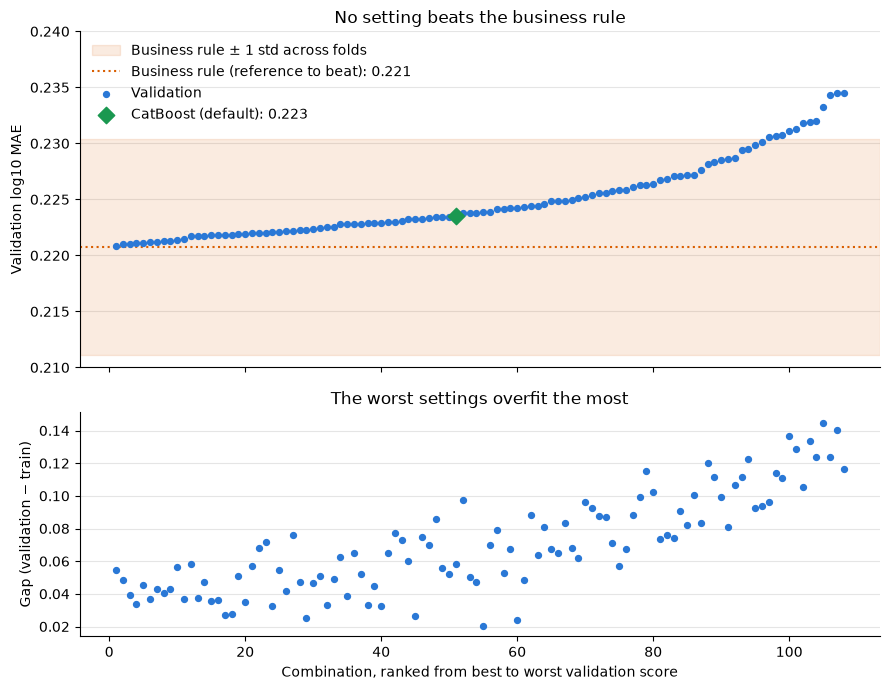

In [74]:
# The 108 combinations ranked from best to worst validation score
ranked = search.sort_values("mean_test_neg_log10_mae", ascending=False)
rank = np.arange(1, len(ranked) + 1)
val_mae = -ranked["mean_test_neg_log10_mae"].to_numpy()
train_mae = -ranked["mean_train_neg_log10_mae"].to_numpy()
gap = val_mae - train_mae

rule_mae = results.loc["Business rule (area x type)", "log10_mae_val_mean"]
rule_std = results.loc["Business rule (area x type)", "log10_mae_val_std"]
default_mae = results.loc["CatBoost (default)", "log10_mae_val_mean"]
default_rank = 1 + (val_mae < default_mae).sum()  # where the default would be ranked

fig, (ax_top, ax_bottom) = plt.subplots(
    2, 1, figsize=(9, 7), sharex=True, gridspec_kw={"height_ratios": [3, 2]}
)

# Top: validation alone, zoomed in
ax_top.axhspan(
    rule_mae - rule_std,
    rule_mae + rule_std,
    color="#d95f02",
    alpha=0.12,
    label="Business rule ± 1 std across folds",
)
ax_top.axhline(
    rule_mae,
    color="#d95f02",
    linestyle=":",
    linewidth=1.5,
    label=f"Business rule (reference to beat): {FORMATS['log10 MAE'].format(rule_mae)}",
)
ax_top.scatter(rank, val_mae, s=18, color="#2a78d6", label="Validation", zorder=3)
ax_top.scatter(
    default_rank,
    default_mae,
    s=70,
    marker="D",
    color="#1a9850",
    label=f"CatBoost (default): {FORMATS['log10 MAE'].format(default_mae)}",
    zorder=4,
)
ax_top.set_ylim(0.21, max(0.24, val_mae.max() + 0.003))
ax_top.set_ylabel("Validation log10 MAE")
ax_top.set_title("No setting beats the business rule")
ax_top.legend(loc="upper left")

# Bottom: overfitting gap
ax_bottom.scatter(rank, gap, s=18, color="#2a78d6")
ax_bottom.set_ylabel("Gap (validation − train)")
ax_bottom.set_xlabel("Combination, ranked from best to worst validation score")
ax_bottom.set_title("The worst settings overfit the most")

plt.tight_layout()
plt.show()

### Reading the search

- **Tuning reduces the overfitting, not the error:** the gap goes from 0.082 to 0.055, while the validation error barely moves.
- **The search reaches a plateau:** almost all the 108 combinations fall inside the band of the rule ± one std, the best settings are at the edges of the grid but central ones do as well, and the default setting is only about 0.002 behind the best one, so a larger grid is not worth the fitting time.
- **The tuned CatBoost matches the business rule but does not beat it**, in log10 MAE as in kBtu, and Ridge is as good as both.

**Conclusion.** The success criterion is not met: tuning makes CatBoost more stable, not better than the rule. Three candidates go to the final evaluation (the rule, Ridge and the tuned CatBoost); as they cannot be told apart, the choice is based on simplicity and readability (see section 7). The tuned score is slightly optimistic, since the combination was selected on it: the test set gives the unbiased value.

## 7. Final evaluation on the test set

### Decision

**Ridge is selected.** On the cross-validation scores it is on par with the business rule and with the tuned CatBoost, so the choice goes to the model that is the easiest to use:

- it is the simplest and the fastest to fit of the ML models;
- it has virtually no gap between train and validation, so little overfitting;
- it is directly readable: its coefficient can be inspected.

**The business rule remains the benchmark.** It is what the city could compute without machine learning, and a model is only worth deploying if it does better. It stays in the comparison, with the dummy model as a floor, next to Ridge and the tuned CatBoost.

**The test set checks the choice, it does not make it.** The choice is made here, before looking at the test set. The test verifies that the cross-validation performance holds up on buildings the models have never seen. It does not distinguish between the models: if the three candidates are again close, that confirms the reading of the cross-validation, and the choice of Ridge is not changed by small differences in the test.

### Test-set scores

The dummy model, the business rule, Ridge and the tuned CatBoost are fitted on the whole training set (the grid search already refitted the tuned CatBoost), then evaluated once on the test set with the same scorers as in the cross-validation. The second table puts the cross-validation and test scores side by side: the test should confirm the cross-validation, not change the ranking.

In [75]:
final_models = {
    "Dummy (mean of log10)": clone(baselines["Dummy (mean of log10)"]),
    "Business rule (area x type)": clone(baselines["Business rule (area x type)"]),
    "Ridge (alpha=1)": clone(models["Ridge (alpha=1)"]),
}
for model in final_models.values():
    model.fit(X_train, y_train)
final_models["CatBoost (tuned)"] = grid.best_estimator_  # already refitted on X_train


def test_scores(model: Any, X: pd.DataFrame, y: pd.Series) -> dict[str, float]:
    """Score a fitted model with the scorers of the cross-validation (errors in positive)."""
    row = {}
    for key, scorer in scorers.items():
        scorer = get_scorer(scorer) if isinstance(scorer, str) else scorer
        sign = -1 if key.startswith("neg_") else 1
        row[key.removeprefix("neg_")] = sign * scorer(model, X, y)
    return row


test_results = pd.DataFrame(
    {name: test_scores(model, X_test, y_test) for name, model in final_models.items()}
).T

test_table = pd.DataFrame(
    {
        "log10 MAE": test_results["log10_mae"],
        "within ±25%": test_results["within_25"],
        "within ±50%": test_results["within_50"],
        "median error": test_results["median_ape"],
        "R2": test_results["r2"],
        "MAE (kBtu)": test_results["mean_absolute_error"],
        "RMSE (kBtu)": test_results["root_mean_squared_error"],
        "total bias": test_results["total_bias"],
    }
)
display(
    styled(test_table).highlight_min(subset=["log10 MAE"], props="font-weight: bold")
)

# Cross-validation (training set) vs test
cv_vs_test = pd.DataFrame(
    {
        "log10 MAE (CV)": results_tuned["log10_mae_val_mean"],
        "log10 MAE (test)": test_table["log10 MAE"],
        "within ±25% (CV)": results_tuned["within_25_val_mean"],
        "within ±25% (test)": test_table["within ±25%"],
        "total bias (CV)": results_tuned["total_bias_val_mean"],
        "total bias (test)": test_table["total bias"],
    }
).loc[list(final_models)]
styled(cv_vs_test)

,log10 MAE,within ±25%,within ±50%,median error,R2,MAE (kBtu),RMSE (kBtu),total bias
Dummy (mean of log10),0.460,15%,30%,79%,-0.040,"8,167,503","32,430,606",-67.2%
Business rule (area x type),0.227,37%,62%,36%,0.193,"5,544,747","28,571,714",-28.9%
Ridge (alpha=1),0.219,36%,63%,37%,0.215,"5,422,120","28,175,284",-26.8%
CatBoost (tuned),0.216,37%,63%,38%,0.185,"5,224,458","28,707,551",-32.7%


,log10 MAE (CV),log10 MAE (test),within ±25% (CV),within ±25% (test),total bias (CV),total bias (test)
Dummy (mean of log10),0.451,0.460,14%,15%,-60.7%,-67.2%
Business rule (area x type),0.221,0.227,37%,37%,-10.9%,-28.9%
Ridge (alpha=1),0.218,0.219,35%,36%,-11.4%,-26.8%
CatBoost (tuned),0.221,0.216,35%,37%,-17.1%,-32.7%


### Predicted vs actual

One panel per candidate, in `log10` so that small and large buildings have the same weight. The solid line is a perfect prediction, the dashed and dotted lines are the ±25% and ±50% tolerances of the tables above. The circled point is the highest energy use building of the test set.

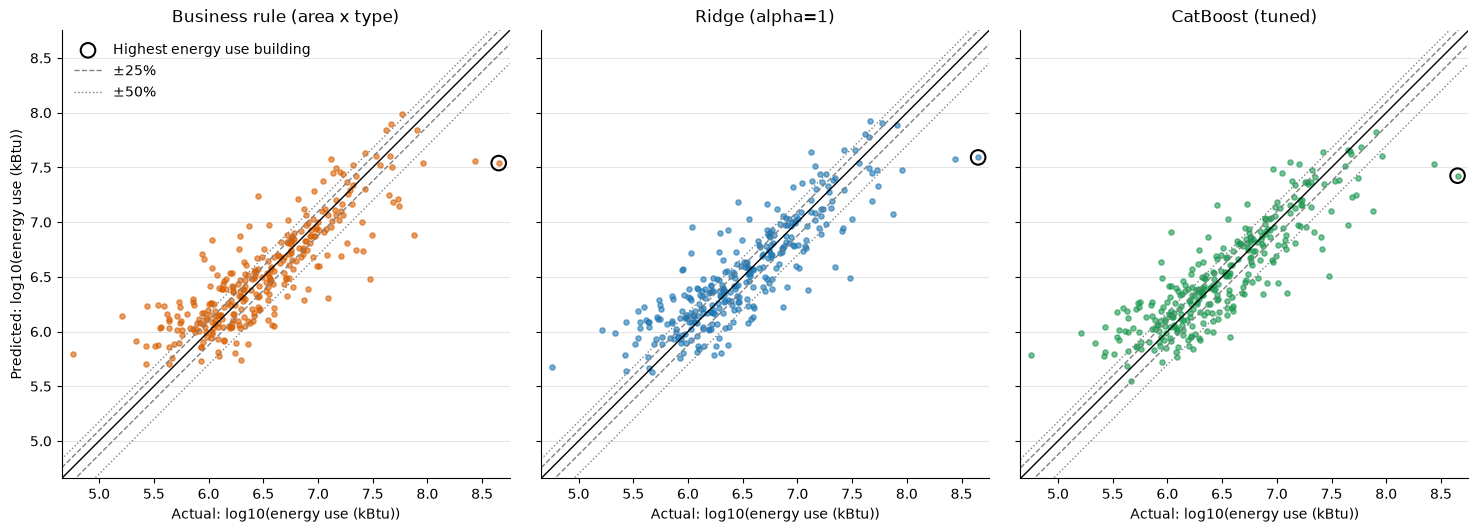

In [76]:
candidates = {
    "Business rule (area x type)": "#d95f02",
    "Ridge (alpha=1)": "#1f77b4",
    "CatBoost (tuned)": "#1a9850",
}
test_pred = {
    name: pd.Series(final_models[name].predict(X_test), index=y_test.index)
    for name in candidates
}

log_actual = np.log10(y_test)
largest = y_test.idxmax()
lo = min(log_actual.min(), *(np.log10(p).min() for p in test_pred.values())) - 0.1
hi = max(log_actual.max(), *(np.log10(p).max() for p in test_pred.values())) + 0.1

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
for ax, (name, color) in zip(axes, candidates.items()):
    log_pred = np.log10(test_pred[name])
    ax.scatter(log_actual, log_pred, s=14, alpha=0.6, color=color)
    ax.scatter(
        log_actual[largest],
        log_pred[largest],
        s=110,
        facecolors="none",
        edgecolors="k",
        linewidths=1.5,
        label="Highest energy use building",
    )
    ax.plot([lo, hi], [lo, hi], "k-", linewidth=1)
    for tol, style in [(0.25, "--"), (0.5, ":")]:
        for factor in (1 + tol, 1 - tol):
            ax.plot(
                [lo, hi],
                [lo + np.log10(factor), hi + np.log10(factor)],
                color="grey",
                linestyle=style,
                linewidth=1,
                label=f"±{tol:.0%}" if factor > 1 else None,
            )
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_aspect("equal")
    ax.set_title(name)
    ax.set_xlabel("Actual: log10(energy use (kBtu))")
axes[0].set_ylabel("Predicted: log10(energy use (kBtu))")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

### The largest errors of Ridge

The 10 buildings with the largest absolute error in kBtu (the errors that dominate the RMSE and the R²), and the share of the total squared error carried by the first `k` of them.

In [77]:
ridge_pred = test_pred["Ridge (alpha=1)"]
abs_error = (ridge_pred - y_test).abs().sort_values(ascending=False)
worst = abs_error.head(10).index

# Energy use per sq ft; the median of each type is computed on the training set
area = X_test.loc[worst, "PropertyGFABuilding(s)"]
type_median_intensity = (
    (y_train / X_train["PropertyGFABuilding(s)"])
    .groupby(X_train["PrimaryPropertyType"])
    .median()
)
worst_types = X_test.loc[worst, "PrimaryPropertyType"]

worst_table = pd.DataFrame(
    {
        "Actual": y_test[worst],
        "Predicted": ridge_pred[worst],
        "Predicted/Actual ratio": ridge_pred[worst] / y_test[worst],
        "Type": worst_types,
        "Area": area,
        "Actual intensity (kBtu/sq ft)": y_test[worst] / area,
        "Median intensity of the type (kBtu/sq ft)": worst_types.map(
            type_median_intensity
        ),
    }
).reset_index(drop=True)
display(styled(worst_table))

# Share of the total squared error carried by the k largest errors
squared_error = abs_error**2
cumulative_share = pd.DataFrame(
    [[squared_error.iloc[:k].sum() / squared_error.sum() for k in (1, 3, 5, 10)]],
    columns=[f"k = {k}" for k in (1, 3, 5, 10)],
    index=["Share of the total squared error"],
)
cumulative_share.style.format("{:.0%}")

,Actual,Predicted,Predicted/Actual ratio,Type,Area,Actual intensity (kBtu/sq ft),Median intensity of the type (kBtu/sq ft)
0,"448,385,312","39,041,655",0.09,Mixed Use Property,"494,835",906,70
1,"274,682,208","37,351,798",0.14,Other,"429,405",640,83
2,"75,073,888","11,830,214",0.16,Mixed Use Property,"108,912",689,70
3,"90,609,640","30,116,819",0.33,University,"537,000",169,64
4,"46,510,960","84,012,098",1.81,Other,"947,987",49,83
5,"55,073,120","21,219,316",0.39,Mixed Use Property,"200,783",274,70
6,"48,406,556","15,687,982",0.32,Large Office,"287,819",168,53
7,"13,270,687","43,932,902",3.31,Large Office,"706,176",19,53
8,"30,038,490","3,111,506",0.10,Other,"36,000",834,83
9,"53,466,684","30,014,024",0.56,Large Office,"302,494",177,53


,k = 1,k = 3,k = 5,k = 10
Share of the total squared error,69%,94%,96%,97%


### The three largest errors in the raw data

The processed files have no building ID, so the three buildings were recovered in the raw file `data/raw/2016_Building_Energy_Benchmarking.csv` by matching their energy use, latitude and longitude (each one has exactly one match).

| Building (ID) | Building type | Primary type (used by the models) | Actual energy use | Largest use | 2nd largest use | 3rd largest use | All use types |
|---|---|---|---|---|---|---|---|
| Plant 2 Site (43) | Campus | Mixed Use Property | 448 M kBtu | Office | Laboratory | Non-Refrigerated Warehouse | Energy/Power Station, Laboratory, Manufacturing/Industrial Plant, Non-Refrigerated Warehouse, Office |
| WestinBuilding (753) | NonResidential | Other | 275 M kBtu | Data Center | Office | none | Data Center, Office |
| Fisher Plaza - West Building (440) | NonResidential | Mixed Use Property | 75 M kBtu | Parking | Data Center | Office | Data Center, Financial Office, Office, Other, Parking, Restaurant |

### Why the models are so wrong on these buildings, and what they weigh in the score

The models only see the area and the primary type of a building. These three buildings are labelled "Mixed Use Property" or "Other", but they contain very energy-intensive uses: an energy/power station, laboratories and a manufacturing plant for the first one, a data center for the two others. Their energy use per sq ft is 8 to 13 times the median of their type, so a model that predicts a typical intensity for the area and the type underestimates them by a factor of 6 to 11. Nothing in the features can tell these buildings apart from an ordinary mixed-use building.

They are 3 buildings out of 307 (1%), but they carry 94% of the squared error of Ridge. Since RMSE and R² are computed on squared errors, they are almost entirely determined by these three buildings, which explains the low R² and the large negative bias on the test set. The table below gives the same metrics for the three candidates, with and without them.

In [78]:
# The 3 buildings with the largest errors of Ridge (see the table above)
top3 = worst[:3]
kept = y_test.index.difference(top3)


def kbtu_scores(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred),
        "RMSE (kBtu)": root_mean_squared_error(y_true, y_pred),
        "total bias": total_bias(y_true, y_pred),
    }


rows = {}
for name in candidates:
    all_scores = kbtu_scores(y_test, test_pred[name])
    kept_scores = kbtu_scores(y_test[kept], test_pred[name][kept])
    rows[name] = {
        f"{metric} ({label})": scores[metric]
        for metric in all_scores
        for label, scores in (("all", all_scores), ("without the 3", kept_scores))
    }
effect_of_top3 = pd.DataFrame(rows).T
styled(effect_of_top3)

,R2 (all),R2 (without the 3),RMSE (kBtu) (all),RMSE (kBtu) (without the 3),total bias (all),total bias (without the 3)
Business rule (area x type),0.193,0.568,"28,571,714","7,658,272",-28.9%,-5.7%
Ridge (alpha=1),0.215,0.616,"28,175,284","7,214,568",-26.8%,-3.2%
CatBoost (tuned),0.185,0.679,"28,707,551","6,598,365",-32.7%,-10.7%


**Reading.** Without these three buildings, the metrics in kBtu are much closer to the cross-validation ones: the R² goes back to about 0.6 to 0.7 and the total bias falls to a few percent. The poor R² of the test set therefore does not mean that the models are bad for a typical building: it comes from three buildings with uses that the features do not describe. The order of the models in kBtu changes once they are removed, but it rests on one split and 304 buildings, so it is not used to change the choice of Ridge, which was made on simplicity and readability.

These buildings were selected because of their errors, so the scores without them are optimistic by construction: they show how much the three buildings weigh, not the true performance. The official test scores are those on all buildings.

### Conclusion

- **The logarithmic metrics confirm the cross-validation, and no model clearly outperforms the rule.** On the test set, the three candidates stay close to each other and to their cross-validation scores, and the share of buildings within ±25% is about the same. Ridge is retained, as decided before the test, for its simplicity and readability.
- **The metrics in kBtu are driven by 3 buildings.** They carry 94% of the squared error of Ridge, so the R², the RMSE and the total bias of the test set say little about a typical building. Without them, these metrics are much closer to the cross-validation ones.
- **All three have an energy-intensive use that is not visible in the primary type.** An energy/power station, laboratories and a manufacturing plant, or a data center, inside a building labelled "Mixed Use Property" or "Other".
- **Outlook.** Build usage flags from `ListOfAllPropertyUseTypes` (for example the presence of a data center, a laboratory or a power station), so that the models can see these uses.

## 8. Feature importance

Permutation importance of the selected model (Ridge) on the test set: each of the 11 input features is shuffled in turn, and its importance is the increase of the `log10` MAE (the decision metric) caused by the shuffle. A feature matters if the model does worse without its information. Shuffling a categorical feature shuffles all its one-hot columns together.

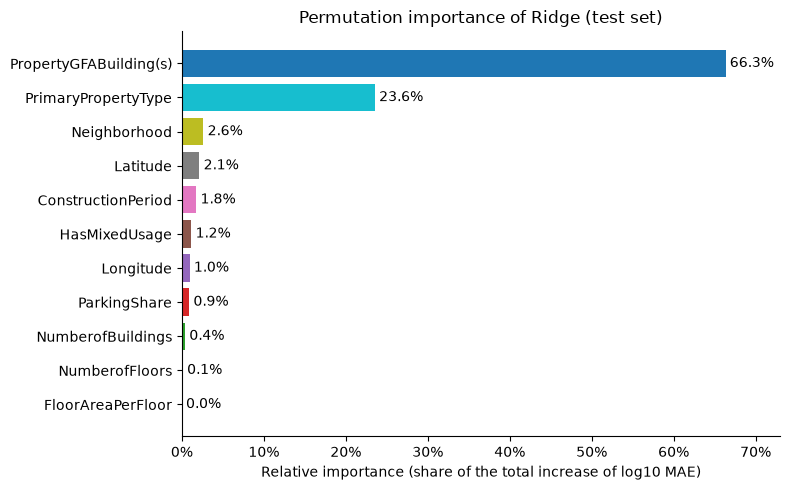

In [88]:
perm = permutation_importance(
    final_models["Ridge (alpha=1)"],
    X_test,
    y_test,
    scoring=scorers["neg_log10_mae"],
    n_repeats=30,
    random_state=RANDOM_STATE,
)
importance = pd.Series(perm.importances_mean, index=X_test.columns)
relative_importance = (importance / importance.sum()).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
colors = sns.color_palette("tab10", len(relative_importance))
bars = ax.barh(relative_importance.index, relative_importance, color=colors)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in relative_importance], padding=3)
ax.margins(x=0.1)
ax.xaxis.set_major_formatter("{x:.0%}")
ax.grid(axis="y", visible=False)
ax.set_xlabel("Relative importance (share of the total increase of log10 MAE)")
ax.set_title("Permutation importance of Ridge (test set)")
plt.tight_layout()
plt.show()

**Reading.** The area comes first, followed by the primary property type, and together they account for about 90% of the importance: Ridge relies mostly on the same two signals as the business rule, the other features add little information, which is consistent with Ridge not doing clearly better than the rule. The other features are negligible. `FloorAreaPerFloor` has an importance of zero because the linear preprocessor drops it.